# 4 · Solving a graph problem with atoms

**The blockade is a constraint solver.** Place atoms on the vertices of a graph so that
blockaded pairs are exactly its edges (a *unit-disk graph*). Then "as many Rydberg atoms as
possible, no two neighbours both excited" is the **Maximum Independent Set** (MIS) problem.
It is NP-hard in general and turns up in scheduling, wireless network design and
portfolio selection. An adiabatic sweep prepares the ground state, which *is* the MIS;
see Ebadi *et al.*, Science 376, 1209 (2022).

Here a 12-vertex graph is cut from the calibrated layout. We compare sweep speeds, and we
are honest about the classical side: at this size a laptop solves it exactly in
milliseconds. What carries over to large graphs is the *method*, and whether it beats
classical heuristics at scale is an open research question.

In [1]:
# Setup: needs the "Python 3 [Pasqal]" kernel (qBraid environment "Pasqal (Pulser)").
import sys, json, pathlib
try:
    import pulser, qbraid
except ImportError:
    raise SystemExit('Switch the kernel to "Python 3 [Pasqal]" (Kernel > Change Kernel), '
                     'or install the environment with: qbraid envs install pasqal_js2dr3')
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from pasqal_atoms import *
print("pulser", pulser.__version__, "| qbraid", qbraid.__version__)

pulser 1.10.0 | qbraid 0.13.1


### Where to run

| `TARGET` | Runs on | Cost | Atoms |
|---|---|---|---|
| `"local"` | exact simulation on this machine (`pulser-simulation`) | free | up to ~12 |
| `"emu"` | Pasqal's **EMU_FREE** cloud emulator, through qBraid | free | up to 12 |
| `"qpu"` | Pasqal's **FRESNEL_CAN1** neutral-atom QPU, through qBraid | per minute of QPU time | up to 100 |

The sequences are built on FRESNEL_CAN1's real device specs and calibrated layout, so the
*same* object runs on all three. Start with `"emu"`; switch to `"qpu"` only after the
emulator result looks right and you have checked the estimate below.

graph: 12 vertices, 22 edges | exact MIS size 5, unique: True | brute force took 0.9 ms


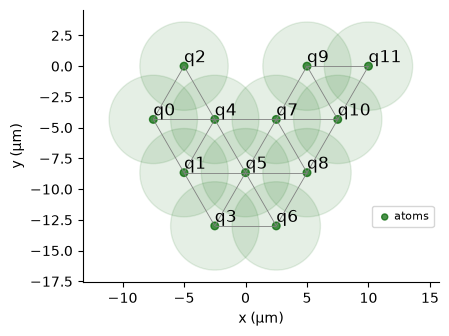

In [2]:
TARGET = "emu"
SHOTS = 500
OMEGA = 2 * np.pi * 1.0
DELTA_START, DELTA_END = -2 * np.pi * 2.5, 2 * np.pi * 2.0
TRAPS = [15, 19, 20, 23, 24, 28, 32, 33, 37, 38, 42, 47]
reg = layout_register(TRAPS)
E = unit_disk_edges(TRAPS)
import time as _t
t0 = _t.perf_counter(); k, best = max_independent_sets(len(TRAPS), E); t_bf = _t.perf_counter() - t0
print(f"graph: {len(TRAPS)} vertices, {len(E)} edges | exact MIS size {k}, unique: {len(best) == 1} "
      f"| brute force took {t_bf * 1e3:.1f} ms")
reg.draw(blockade_radius=blockade_radius(OMEGA), draw_half_radius=True)

In [3]:
DURATIONS = [800, 2000, 3500, 5000]      # ns: from a quench to a slow, adiabatic sweep
seqs = [adiabatic_sweep(reg, OMEGA, DELTA_START, DELTA_END, duration=T, rise=min(500, T // 4))
        for T in DURATIONS]
counts = run_many(seqs, target=TARGET, shots=SHOTS)
exact = run_many(seqs, target="local", shots=2000)

submitted:
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6f61cb75925982638b1
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6f71cb75925982638bd
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6f91cb75925982638cb
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6fa1cb75925982638dc


[{'p_mis': 0.026, 'p_independent': 0.994, 'mean_size': 3.338, 'best_found': 5}, {'p_mis': 0.246, 'p_independent': 1.0, 'mean_size': 4.116, 'best_found': 5}, {'p_mis': 0.424, 'p_independent': 1.0, 'mean_size': 4.392, 'best_found': 5}, {'p_mis': 0.568, 'p_independent': 1.0, 'mean_size': 4.55, 'best_found': 5}]


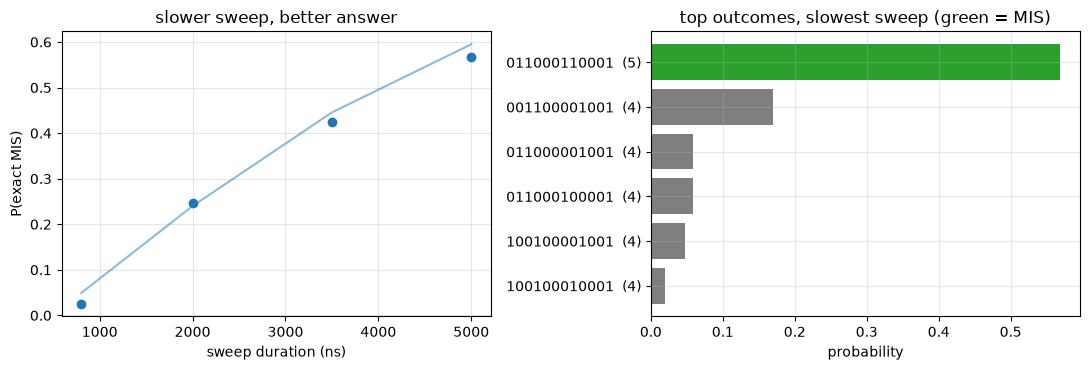

In [4]:
mis_set = set(best)
as_set = lambda b: tuple(i for i, x in enumerate(b) if x == "1")
def score(c):
    indep = {b: v for b, v in c.items() if is_independent(b, E)}
    best_found = max((b.count("1") for b in indep), default=0)
    return {"p_mis": prob(c, lambda b: as_set(b) in mis_set),
            "p_independent": prob(c, lambda b: is_independent(b, E)),
            "mean_size": float(sum(b.count("1") * v for b, v in indep.items()) / max(1, sum(indep.values()))),
            "best_found": best_found}
S, X = [score(c) for c in counts], [score(c) for c in exact]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(DURATIONS, [x["p_mis"] for x in X], "-", alpha=.5, color="C0")
ax[0].plot(DURATIONS, [s["p_mis"] for s in S], "o", color="C0")
ax[0].set(xlabel="sweep duration (ns)", ylabel="P(exact MIS)", title="slower sweep, better answer")
c = counts[-1]
outcomes = top(c, 6)
ax[1].barh([f"{b}  ({b.count('1')})" for b, _ in outcomes][::-1], [v / SHOTS for _, v in outcomes][::-1],
           color=["C2" if as_set(b) in mis_set else "C7" for b, _ in outcomes][::-1])
ax[1].set(xlabel="probability", title="top outcomes, slowest sweep (green = MIS)")
for a in ax: a.grid(alpha=.3)
plt.tight_layout()
print([{k2: round(v, 3) for k2, v in s.items()} for s in S])

**What to see.** A fast sweep (0.8 µs) leaves the atoms in a jumble of valid but small
independent sets: the blockade is never violated, but the answer is poor. Slowing to 5 µs
makes the exact MIS the most likely outcome. The runner-up is a valid 4-atom set, one atom
short. Hardware MIS studies post-process samples, for example with a greedy "fill the holes"
pass, which turns many near-misses into the optimum and takes one line to add.

In [5]:
result = {"chapter": 4, "traps": TRAPS, "edges": E, "mis": k, "mis_sets": best, "omega": OMEGA,
          "delta_start": DELTA_START, "delta_end": DELTA_END, "durations": DURATIONS,
          "target": TARGET, "shots": SHOTS, "emu": S, "exact": X, "classical_ms": t_bf * 1e3,
          "top_slowest": outcomes}
json.dump(result, open(ROOT / "results" / "04_mis.json", "w"), indent=1)

## Run it on the QPU

Everything above ran on the free emulator. The same sequences run unchanged on FRESNEL_CAN1.
QPU time is billed per minute and jobs wait in Pasqal's queue (hours to days), so:

1. Check the estimate (credits; 1 credit = USD 0.01). It is based on ~1.2 s of QPU time per shot.
2. Set `CONFIRM_QPU = True` and run the cell. It submits and prints the job IDs; it does not wait.
3. Come back later: `qbraid jobs get <id>`, or the Lab's **Quantum Jobs** panel.

In [6]:
CONFIRM_QPU = False
QPU_SHOTS = 100
print(qpu_estimate(QPU_SHOTS))
if CONFIRM_QPU:
    job = submit(seqs[-1], "qpu", QPU_SHOTS, confirm_qpu=True)
    print("QPU job ID:", job.id)
    # later: score(wait([job], timeout=7 * 24 * 3600)[0])

{'credits_per_minute': 6358.0, 'est_qpu_seconds': 120.0, 'est_credits': 12716.0, 'est_usd': 127.16}
